In [3]:
from pathlib import Path

ROOT = Path("/mnt/volume/Projects/semantic-state-transition-detection")

DATA_ROOT = ROOT / "data" / "raw" / "clevrer"

for path in sorted(DATA_ROOT.iterdir()):
    kind = "directory" if path.is_dir() else "file"
    print(f"{kind:10} {path.name}")

directory  annotations
directory  derender_proposals
directory  downloads
directory  questions
directory  test
directory  train
directory  validation


### Count the files in each split.

In [7]:
from collections import Counter

splits = ["train", "validation", "test"]

for split in splits:
    split_path = DATA_ROOT / split

    if not split_path.exists():
        print(f"{split}: directory not found")
        continue

    files = [p for p in split_path.rglob("*") if p.is_file()]
    extensions = Counter(p.suffix.lower() or "[no extension]" for p in files)

    print(f"\n{split.upper()}")
    print(f"Total files: {len(files)}")
    print("File types:", dict(extensions))


TRAIN
Total files: 10000
File types: {'.mp4': 10000}

VALIDATION
Total files: 5000
File types: {'.mp4': 5000}

TEST
Total files: 5000
File types: {'.mp4': 5000}


In [8]:
from collections import Counter

annotation_root = DATA_ROOT / "annotations"

for path in sorted(annotation_root.rglob("*")):
    if path.is_file():
        print(
            f"{path.relative_to(annotation_root)}"
            f"  |  {path.stat().st_size / 1024:.1f} KB"
        )

train/annotation_00000-01000/annotation_00000.json  |  155.3 KB
train/annotation_00000-01000/annotation_00001.json  |  108.0 KB
train/annotation_00000-01000/annotation_00002.json  |  107.0 KB
train/annotation_00000-01000/annotation_00003.json  |  104.1 KB
train/annotation_00000-01000/annotation_00004.json  |  155.8 KB
train/annotation_00000-01000/annotation_00005.json  |  132.3 KB
train/annotation_00000-01000/annotation_00006.json  |  132.0 KB
train/annotation_00000-01000/annotation_00007.json  |  155.8 KB
train/annotation_00000-01000/annotation_00008.json  |  131.8 KB
train/annotation_00000-01000/annotation_00009.json  |  131.2 KB
train/annotation_00000-01000/annotation_00010.json  |  131.0 KB
train/annotation_00000-01000/annotation_00011.json  |  131.5 KB
train/annotation_00000-01000/annotation_00012.json  |  154.8 KB
train/annotation_00000-01000/annotation_00013.json  |  132.0 KB
train/annotation_00000-01000/annotation_00014.json  |  131.5 KB
train/annotation_00000-01000/annotation_

In [9]:
from pathlib import Path

annotation_root = DATA_ROOT / "annotations"

files = sorted(p for p in annotation_root.rglob("*") if p.is_file())

print(f"Total annotation files: {len(files)}")

for path in files[:40]:
    print(
        f"{path.relative_to(annotation_root)}"
        f"  |  {path.stat().st_size / 1024:.1f} KB"
    )

if len(files) > 40:
    print(f"... and {len(files) - 40} more files")

Total annotation files: 15000
train/annotation_00000-01000/annotation_00000.json  |  155.3 KB
train/annotation_00000-01000/annotation_00001.json  |  108.0 KB
train/annotation_00000-01000/annotation_00002.json  |  107.0 KB
train/annotation_00000-01000/annotation_00003.json  |  104.1 KB
train/annotation_00000-01000/annotation_00004.json  |  155.8 KB
train/annotation_00000-01000/annotation_00005.json  |  132.3 KB
train/annotation_00000-01000/annotation_00006.json  |  132.0 KB
train/annotation_00000-01000/annotation_00007.json  |  155.8 KB
train/annotation_00000-01000/annotation_00008.json  |  131.8 KB
train/annotation_00000-01000/annotation_00009.json  |  131.2 KB
train/annotation_00000-01000/annotation_00010.json  |  131.0 KB
train/annotation_00000-01000/annotation_00011.json  |  131.5 KB
train/annotation_00000-01000/annotation_00012.json  |  154.8 KB
train/annotation_00000-01000/annotation_00013.json  |  132.0 KB
train/annotation_00000-01000/annotation_00014.json  |  131.5 KB
train/anno

In [10]:

import json
from pathlib import Path

annotation_root = DATA_ROOT / "annotations"

candidates = sorted(
    p for p in annotation_root.rglob("*")
    if p.is_file() and p.suffix.lower() == ".json"
)

if not candidates:
    print("No JSON annotation files found.")
    print("Annotation files may use another format; inspect the file listing.")
else:
    path = candidates[0]
    print(f"File: {path.relative_to(DATA_ROOT)}")
    print(f"Size: {path.stat().st_size / 1024:.1f} KB\n")

    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))
        print(json.dumps(data, indent=2)[:6000])
    elif isinstance(data, list):
        print("Number of entries:", len(data))
        if data:
            print(json.dumps(data[0], indent=2)[:6000])
    else:
        print(repr(data)[:6000])


File: annotations/train/annotation_00000-01000/annotation_00000.json
Size: 155.3 KB

Top-level type: dict
Top-level keys: ['scene_index', 'video_filename', 'object_property', 'motion_trajectory', 'collision']
{
  "scene_index": 0,
  "video_filename": "video_00000.mp4",
  "object_property": [
    {
      "object_id": 0,
      "color": "blue",
      "material": "rubber",
      "shape": "sphere"
    },
    {
      "object_id": 1,
      "color": "gray",
      "material": "rubber",
      "shape": "sphere"
    },
    {
      "object_id": 2,
      "color": "cyan",
      "material": "metal",
      "shape": "cube"
    },
    {
      "object_id": 3,
      "color": "purple",
      "material": "rubber",
      "shape": "sphere"
    },
    {
      "object_id": 4,
      "color": "blue",
      "material": "metal",
      "shape": "sphere"
    },
    {
      "object_id": 5,
      "color": "yellow",
      "material": "rubber",
      "shape": "cylinder"
    }
  ],
  "motion_trajectory": [
    {
      "fra

In [11]:

import json
from pathlib import Path

annotation_path = (
    DATA_ROOT
    / "annotations/train/annotation_00000-01000/annotation_00000.json"
)

with annotation_path.open("r", encoding="utf-8") as f:
    ann = json.load(f)

# Inspect collision annotation structure
collision = ann.get("collision")
print("=== COLLISION ===")
print(json.dumps(collision, indent=2)[:5000])

# Inspect trajectory coverage
trajectory = ann.get("motion_trajectory", [])
print("\n=== TRAJECTORY ===")
print("Number of annotated frames:", len(trajectory))

if trajectory:
    print("First frame ID:", trajectory[0].get("frame_id"))
    print("Last frame ID:", trajectory[-1].get("frame_id"))

    first_objects = trajectory[0].get("objects", [])
    print("Objects in first frame:", len(first_objects))

    if first_objects:
        print("Per-object fields:", list(first_objects[0].keys()))


=== COLLISION ===
[
  {
    "object_ids": [
      0,
      1
    ],
    "frame_id": 19,
    "location": [
      0.1717,
      -1.5228,
      0.2008
    ]
  },
  {
    "object_ids": [
      1,
      2
    ],
    "frame_id": 39,
    "location": [
      0.3383,
      -0.4383,
      0.2008
    ]
  },
  {
    "object_ids": [
      1,
      3
    ],
    "frame_id": 71,
    "location": [
      -0.8001,
      -0.6587,
      0.2009
    ]
  }
]

=== TRAJECTORY ===
Number of annotated frames: 128
First frame ID: 0
Last frame ID: 127
Objects in first frame: 6
Per-object fields: ['object_id', 'location', 'orientation', 'velocity', 'angular_velocity', 'inside_camera_view']


### Visualize the collision events

Before implementing detection, let's see what happens visually around each annotated collision. We'll extract frames immediately before and after each event and compare them.

Using video: /mnt/volume/Projects/semantic-state-transition-detection/data/raw/clevrer/train/video_00000-01000/video_00000.mp4
Video: video_00000.mp4
Frames: 128 | FPS: 25.00
Collision at frame 19: objects [0, 1]
Collision at frame 39: objects [1, 2]
Collision at frame 71: objects [1, 3]


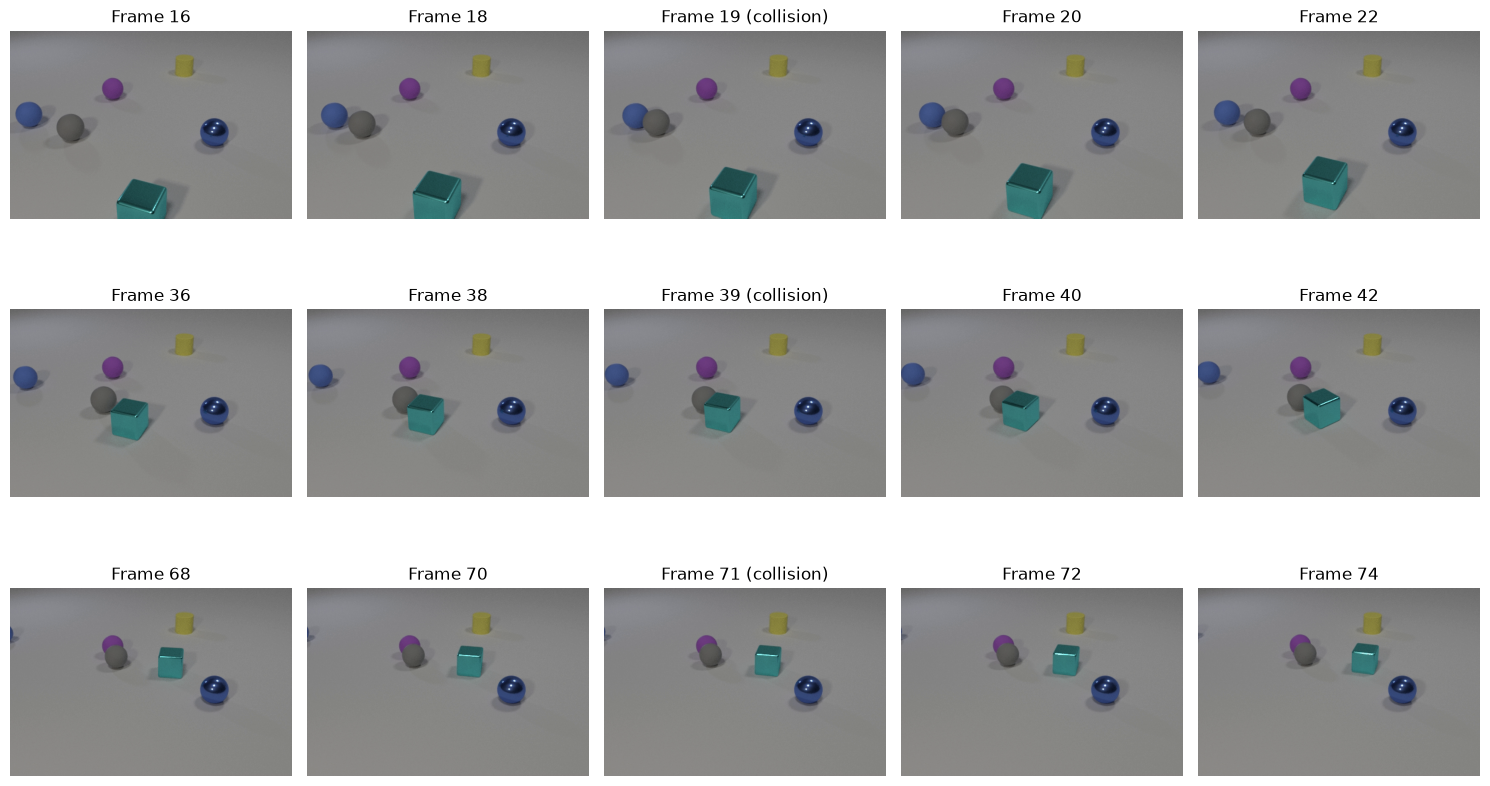

In [13]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path


video_name = ann["video_filename"]

matches = list((DATA_ROOT / "train").rglob(video_name))

if not matches:
    raise FileNotFoundError(
        f"{video_name} not found under {DATA_ROOT / 'train'}"
    )

video_path = matches[0]
print(f"Using video: {video_path}")


if not video_path.exists():
    print(f"Video not found: {video_path}")
else:
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"Video: {video_path.name}")
    print(f"Frames: {total_frames} | FPS: {fps:.2f}")

    offsets = [-3, -1, 0, 1, 3]

    fig, axes = plt.subplots(
        len(events), len(offsets),
        figsize=(15, 3 * len(events))
    )

    for row, event in enumerate(events):
        collision_frame = event["frame_id"]

        for col, offset in enumerate(offsets):
            frame_id = collision_frame + offset
            ax = axes[row, col]

            if not 0 <= frame_id < total_frames:
                ax.set_visible(False)
                continue

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
            ok, frame = cap.read()

            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                ax.imshow(frame)
                ax.set_title(
                    f"Frame {frame_id}"
                    + (" (collision)" if offset == 0 else "")
                )

            ax.axis("off")

        print(
            f"Collision at frame {collision_frame}: "
            f"objects {event['object_ids']}"
        )

    cap.release()
    plt.tight_layout()
    plt.show()


In [14]:

import numpy as np
import pandas as pd

trajectory = {
    frame["frame_id"]: {
        obj["object_id"]: obj
        for obj in frame["objects"]
    }
    for frame in ann["motion_trajectory"]
}

rows = []

for event in ann["collision"]:
    frame_id = event["frame_id"]

    for object_id in event["object_ids"]:
        before = trajectory.get(frame_id - 1, {}).get(object_id)
        at_event = trajectory.get(frame_id, {}).get(object_id)
        after = trajectory.get(frame_id + 1, {}).get(object_id)

        if not (before and at_event and after):
            continue

        v_before = np.array(before["velocity"], dtype=float)
        v_event = np.array(at_event["velocity"], dtype=float)
        v_after = np.array(after["velocity"], dtype=float)

        rows.append({
            "collision_frame": frame_id,
            "object_id": object_id,
            "collision_time_s": round(frame_id / fps, 3),
            "speed_before": round(np.linalg.norm(v_before), 3),
            "speed_at_event": round(np.linalg.norm(v_event), 3),
            "speed_after": round(np.linalg.norm(v_after), 3),
            "velocity_change": round(
                np.linalg.norm(v_after - v_before), 3
            ),
        })

event_table = pd.DataFrame(rows)
display(event_table)


,collision_frame,object_id,collision_time_s,speed_before,speed_at_event,speed_after,velocity_change
0,19,0,0.76,2.657,2.646,1.727,4.141
1,19,1,0.76,2.638,2.627,1.352,3.686
2,39,1,1.56,1.290,1.286,0.975,1.571
3,39,2,1.56,2.123,2.108,1.511,1.520
4,71,1,2.84,0.913,0.572,0.547,0.390
5,71,3,2.84,0.000,0.446,0.480,0.480


In [15]:

print("Collision annotations:")
for event in ann["collision"]:
    print(
        "frame =", event["frame_id"],
        "| objects =", event["object_ids"]
    )

print("\nTrajectory frame range:")
frame_ids = sorted(trajectory.keys())
print(min(frame_ids), "to", max(frame_ids))

print("\nRecomputed event table:")
rows = []

for event in ann["collision"]:
    f = event["frame_id"]

    for oid in event["object_ids"]:
        before = trajectory.get(f - 1, {}).get(oid)
        at = trajectory.get(f, {}).get(oid)
        after = trajectory.get(f + 1, {}).get(oid)

        if not all([before, at, after]):
            print(f"Missing trajectory: frame={f}, object={oid}")
            continue

        vb = np.array(before["velocity"], dtype=float)
        ve = np.array(at["velocity"], dtype=float)
        va = np.array(after["velocity"], dtype=float)

        rows.append({
            "collision_frame": f,
            "object_id": oid,
            "time_seconds": round(f / fps, 3),
            "speed_before": round(np.linalg.norm(vb), 3),
            "speed_at_event": round(np.linalg.norm(ve), 3),
            "speed_after": round(np.linalg.norm(va), 3),
            "velocity_change": round(np.linalg.norm(va - vb), 3),
        })

display(pd.DataFrame(rows))


Collision annotations:
frame = 19 | objects = [0, 1]
frame = 39 | objects = [1, 2]
frame = 71 | objects = [1, 3]

Trajectory frame range:
0 to 127

Recomputed event table:


,collision_frame,object_id,time_seconds,speed_before,speed_at_event,speed_after,velocity_change
0,19,0,0.76,2.657,2.646,1.727,4.141
1,19,1,0.76,2.638,2.627,1.352,3.686
2,39,1,1.56,1.290,1.286,0.975,1.571
3,39,2,1.56,2.123,2.108,1.511,1.520
4,71,1,2.84,0.913,0.572,0.547,0.390
5,71,3,2.84,0.000,0.446,0.480,0.480


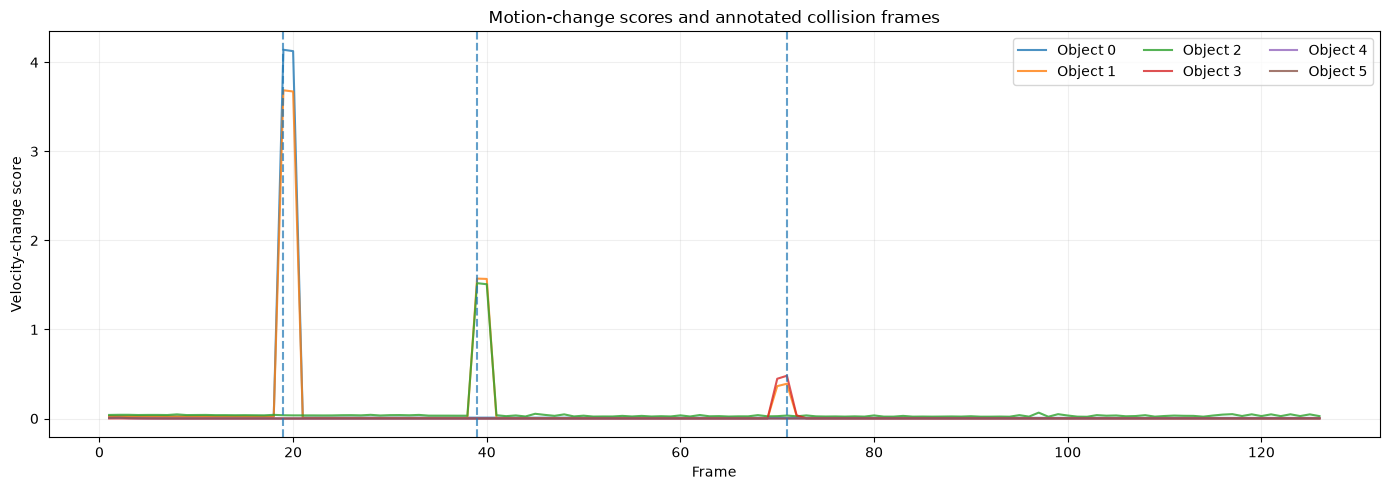

In [16]:

import numpy as np
import matplotlib.pyplot as plt

frame_ids = sorted(trajectory.keys())
object_ids = sorted({
    oid
    for frame in trajectory.values()
    for oid in frame.keys()
})

scores = {oid: {} for oid in object_ids}

for oid in object_ids:
    for f in frame_ids:
        before = trajectory.get(f - 1, {}).get(oid)
        after = trajectory.get(f + 1, {}).get(oid)

        if before is None or after is None:
            continue

        vb = np.array(before["velocity"], dtype=float)
        va = np.array(after["velocity"], dtype=float)

        scores[oid][f] = np.linalg.norm(va - vb)

plt.figure(figsize=(14, 5))

for oid in object_ids:
    fs = sorted(scores[oid])
    values = [scores[oid][f] for f in fs]
    plt.plot(fs, values, label=f"Object {oid}", alpha=0.8)

for event in ann["collision"]:
    plt.axvline(
        event["frame_id"],
        linestyle="--",
        alpha=0.7
    )

plt.xlabel("Frame")
plt.ylabel("Velocity-change score")
plt.title("Motion-change scores and annotated collision frames")
plt.legend(ncol=3)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Dude, this is actually a really promising result for our first baseline. 🔥 Let's understand exactly what the graph tells us and, just as importantly, what it doesn't tell us yet.

## 1. How to read the graph

- X-axis — Frame: Time in the video, from frame 0 to 127.
- Y-axis — Velocity-change score: How much an object's velocity vector changes between frames \\(t-1\\) and \\(t+1\\).
- Colored lines: The motion-change score for each of the six objects.
- Dashed vertical lines: Ground-truth collision frames: 19, 39, and 71.

Our score is:

$$
D_t = \left||\mathbf{v}_{t+1}-\mathbf{v}_{t-1}\right||_{2}
$$

A larger score means a greater change in velocity over that window.

## 2. Interpreting your results

### 1. Collision at frame 19 — strong response

Objects 0 and 1 produce the largest peaks, approximately 4.1 and 3.7. Their motion changes sharply around the annotated collision.

Clear signal

### 2. Collision at frame 39 — moderate response

Objects 1 and 2 have peaks around 1.5. The collision is still visible in the score, but its signal is smaller than the first collision.

Detectable signal

### 3. Collision at frame 71 — weaker response

Objects 1 and 3 produce peaks of roughly 0.4–0.5. A threshold that catches the first collision could miss this one.

Potential false negative

Most other frames have scores close to zero, meaning the objects' velocities remain relatively stable across those two-frame windows.

## 3. What does this mean for our research?

The graph illustrates an important observation:

Motion change can be a useful signal for physical-event detection, but the magnitude of that signal varies between events.

Consider a simple threshold detector:

$$ \hat{y}_t = \begin{cases} 1 & D_t > \tau\\\ 0 & D_t \leq \tau \end{cases} $$

Here, $\tau$ is a threshold chosen to distinguish candidate events from ordinary motion.

- If $\tau$ is too high, weaker events like the collision at frame 71 may be missed.
- If $\tau$ is too low, small movements or noise elsewhere in a video may trigger false detections.

This is precisely the trade-off we'll evaluate across many videos.

One caveat: the graph uses ground-truth velocities from the annotations. It tells us how informative the motion signal can be when velocity is known; it does not yet demonstrate that a vision model can recover that signal from pixels.

## 4. Our next experiment

Let's avoid choosing a threshold based on just these three collisions. Instead, we'll build a small evaluation over multiple annotated videos.

The next steps will be:

1. Calculate motion-change scores for every object in a subset of videos.
2. Combine object scores into a single per-frame event score, for example by taking the maximum across objects.
3. Evaluate several thresholds against annotated collision frames.
4. Measure event precision, recall, and temporal localization error.

That gives us a defensible baseline before introducing the more complex object-state and relationship reasoning in our proposed system.

The key takeaway: this first visualization supports continuing with a motion-change baseline, but we need a multi-video evaluation to establish whether it works reliably.

Annotations selected: 100
Videos successfully processed: 100
Annotated collisions: 246


,threshold,TP,FP,FN,precision,recall,F1
0,0.05,228,257,18,0.470,0.927,0.624
1,0.10,232,70,14,0.768,0.943,0.847
2,0.20,237,43,9,0.846,0.963,0.901
3,0.30,240,33,6,0.879,0.976,0.925
4,0.50,222,11,24,0.953,0.902,0.927
5,0.75,195,2,51,0.990,0.793,0.880
6,1.00,169,0,77,1.000,0.687,0.814
7,1.50,120,0,126,1.000,0.488,0.656
8,2.00,65,0,181,1.000,0.264,0.418


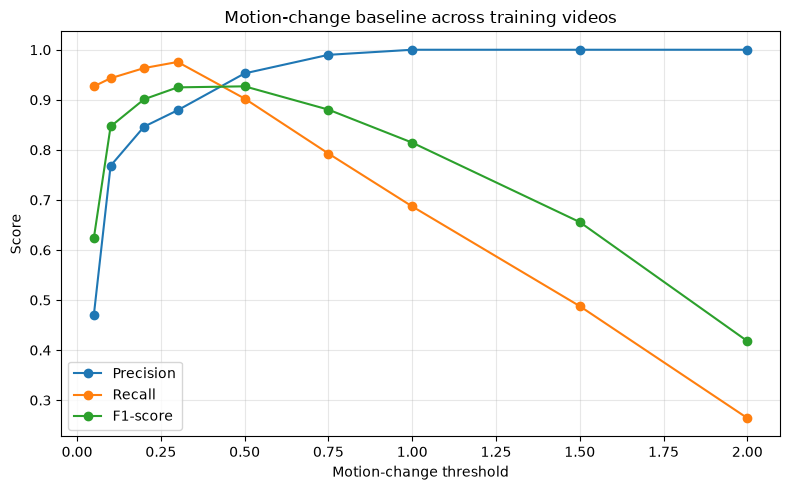

In [17]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
ANNOTATION_ROOT = DATA_ROOT / "annotations" / "train"
MAX_VIDEOS = 100
TOLERANCE = 2
THRESHOLDS = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]

annotation_files = sorted(ANNOTATION_ROOT.rglob("annotation_*.json"))
annotation_files = annotation_files[:MAX_VIDEOS]

print(f"Annotations selected: {len(annotation_files)}")

def load_motion_scores(ann):
    """Return one maximum object motion-change score per frame."""
    frames = {
        frame["frame_id"]: {
            obj["object_id"]: obj
            for obj in frame["objects"]
        }
        for frame in ann["motion_trajectory"]
    }

    if not frames:
        return {}

    scores = {}

    for frame_id in sorted(frames):
        before = frames.get(frame_id - 1, {})
        after = frames.get(frame_id + 1, {})
        object_scores = []

        for object_id in before.keys() & after.keys():
            vb = np.asarray(before[object_id]["velocity"], dtype=float)
            va = np.asarray(after[object_id]["velocity"], dtype=float)
            object_scores.append(float(np.linalg.norm(va - vb)))

        if object_scores:
            scores[frame_id] = max(object_scores)

    return scores


def group_detections(scores, threshold):
    """Merge consecutive above-threshold frames into event intervals."""
    active = sorted(
        frame_id for frame_id, score in scores.items()
        if score >= threshold
    )

    if not active:
        return []

    intervals = []
    start = previous = active[0]

    for frame_id in active[1:]:
        if frame_id > previous + 1:
            intervals.append((start, previous))
            start = frame_id
        previous = frame_id

    intervals.append((start, previous))
    return intervals


def evaluate_video(scores, ground_truth, threshold, tolerance=2):
    """Match each predicted interval to at most one ground-truth event."""
    predictions = group_detections(scores, threshold)
    matched_gt = set()
    true_positives = 0

    for start, end in predictions:
        # Match by distance to the predicted interval
        candidates = [
            (abs(gt - min(max(gt, start), end)), i, gt)
            for i, gt in enumerate(ground_truth)
            if i not in matched_gt
            and start - tolerance <= gt <= end + tolerance
        ]

        if candidates:
            _, gt_index, _ = min(candidates)
            matched_gt.add(gt_index)
            true_positives += 1

    false_positives = len(predictions) - true_positives
    false_negatives = len(ground_truth) - true_positives

    return true_positives, false_positives, false_negatives


# Load annotations and compute per-video scores
videos = []

for path in annotation_files:
    try:
        with path.open("r", encoding="utf-8") as f:
            ann_i = json.load(f)

        scores = load_motion_scores(ann_i)
        collisions = [
            event["frame_id"]
            for event in ann_i.get("collision", [])
        ]

        if scores:
            videos.append({
                "annotation": path.name,
                "scores": scores,
                "collisions": collisions,
            })

    except (OSError, json.JSONDecodeError, KeyError, TypeError) as exc:
        print(f"Skipping {path.name}: {exc}")

print(f"Videos successfully processed: {len(videos)}")
print(f"Annotated collisions: {sum(len(v['collisions']) for v in videos)}")

# Evaluate thresholds across the subset
results = []

for threshold in THRESHOLDS:
    TP = FP = FN = 0

    for video in videos:
        tp, fp, fn = evaluate_video(
            video["scores"],
            video["collisions"],
            threshold,
            TOLERANCE,
        )
        TP += tp
        FP += fp
        FN += fn

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    results.append({
        "threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

plt.figure(figsize=(8, 5))
plt.plot(results_df["threshold"], results_df["precision"],
         marker="o", label="Precision")
plt.plot(results_df["threshold"], results_df["recall"],
         marker="o", label="Recall")
plt.plot(results_df["threshold"], results_df["F1"],
         marker="o", label="F1-score")
plt.xlabel("Motion-change threshold")
plt.ylabel("Score")
plt.title("Motion-change baseline across training videos")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:

print("Videos evaluated:", len(videos))
print("Ground-truth collisions:",
      sum(len(v["collisions"]) for v in videos))

display(results_df.round(4))

best = results_df.loc[results_df["F1"].idxmax()]
print("\nBest threshold on this exploratory subset:")
print(best.to_string())


Videos evaluated: 100
Ground-truth collisions: 246


,threshold,TP,FP,FN,precision,recall,F1
0,0.05,228,257,18,0.4701,0.9268,0.6238
1,0.10,232,70,14,0.7682,0.9431,0.8467
2,0.20,237,43,9,0.8464,0.9634,0.9011
3,0.30,240,33,6,0.8791,0.9756,0.9249
4,0.50,222,11,24,0.9528,0.9024,0.9269
5,0.75,195,2,51,0.9898,0.7927,0.8804
6,1.00,169,0,77,1.0000,0.6870,0.8145
7,1.50,120,0,126,1.0000,0.4878,0.6557
8,2.00,65,0,181,1.0000,0.2642,0.4180



Best threshold on this exploratory subset:
threshold      0.500000
TP           222.000000
FP            11.000000
FN            24.000000
precision      0.952790
recall         0.902439
F1             0.926931


In [19]:

from pathlib import Path

validation_root = DATA_ROOT / "annotations" / "validation"

validation_files = sorted(
    validation_root.rglob("annotation_*.json")
)

print("Validation annotation files:", len(validation_files))

for path in validation_files[:5]:
    print(path.relative_to(DATA_ROOT))


Validation annotation files: 5000
annotations/validation/annotation_10000-11000/annotation_10000.json
annotations/validation/annotation_10000-11000/annotation_10001.json
annotations/validation/annotation_10000-11000/annotation_10002.json
annotations/validation/annotation_10000-11000/annotation_10003.json
annotations/validation/annotation_10000-11000/annotation_10004.json


In [20]:

VALIDATION_LIMIT = 100
FIXED_THRESHOLD = 0.5

validation_subset = validation_files[:VALIDATION_LIMIT]
validation_results = []

for path in validation_subset:
    try:
        with path.open("r", encoding="utf-8") as f:
            val_ann = json.load(f)

        scores = load_motion_scores(val_ann)
        collisions = [
            event["frame_id"]
            for event in val_ann.get("collision", [])
        ]

        if not scores:
            continue

        tp, fp, fn = evaluate_video(
            scores,
            collisions,
            FIXED_THRESHOLD,
            tolerance=TOLERANCE,
        )

        validation_results.append({
            "annotation": path.name,
            "TP": tp,
            "FP": fp,
            "FN": fn,
        })

    except (OSError, json.JSONDecodeError, KeyError, TypeError) as exc:
        print(f"Skipping {path.name}: {exc}")

val_df = pd.DataFrame(validation_results)

TP = int(val_df["TP"].sum()) if not val_df.empty else 0
FP = int(val_df["FP"].sum()) if not val_df.empty else 0
FN = int(val_df["FN"].sum()) if not val_df.empty else 0

precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print("Validation videos processed:", len(val_df))
print("Fixed threshold:", FIXED_THRESHOLD)
print("TP:", TP, "| FP:", FP, "| FN:", FN)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


Validation videos processed: 100
Fixed threshold: 0.5
TP: 236 | FP: 4 | FN: 19
Precision: 0.9833
Recall:    0.9255
F1-score:  0.9535


Dataset root: /mnt/volume/Projects/semantic-state-transition-detection/data/raw/clevrer
Annotation root exists: True
Annotations selected: 100

Videos processed: 100
Videos not found: 0
Videos unreadable: 0
Ground-truth collisions: 246


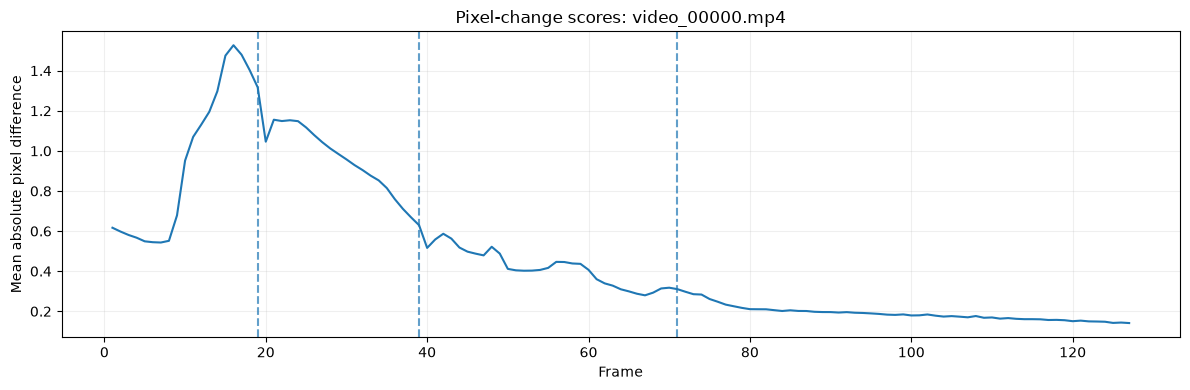

In [22]:

import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# DATA_ROOT should point to data/raw/clevrer
ANNOTATION_ROOT = DATA_ROOT / "annotations" / "train"

MAX_VIDEOS = 100
TOLERANCE = 2

annotation_files = sorted(
    ANNOTATION_ROOT.rglob("annotation_*.json")
)[:MAX_VIDEOS]

print("Dataset root:", DATA_ROOT.resolve())
print("Annotation root exists:", ANNOTATION_ROOT.exists())
print("Annotations selected:", len(annotation_files))


def get_video_path(filename):
    """Find a video anywhere under the CLEVRER dataset root."""
    matches = list(DATA_ROOT.rglob(filename))
    return matches[0] if matches else None


def get_pixel_difference_scores(video_path):
    """
    Calculate mean absolute grayscale pixel differences.
    Score at frame t compares frame t with frame t-1.
    """
    cap = cv2.VideoCapture(str(video_path))
    scores = {}

    if not cap.isOpened():
        cap.release()
        return scores

    ok, previous = cap.read()

    if not ok:
        cap.release()
        return scores

    previous = cv2.cvtColor(previous, cv2.COLOR_BGR2GRAY)
    frame_id = 1

    while True:
        ok, current = cap.read()
        if not ok:
            break

        current = cv2.cvtColor(current, cv2.COLOR_BGR2GRAY)
        difference = cv2.absdiff(current, previous)

        scores[frame_id] = float(np.mean(difference))

        previous = current
        frame_id += 1

    cap.release()
    return scores


def group_detections(scores, threshold):
    """Merge consecutive above-threshold frames into intervals."""
    active = sorted(
        frame for frame, score in scores.items()
        if score >= threshold
    )

    if not active:
        return []

    intervals = []
    start = previous = active[0]

    for frame in active[1:]:
        if frame > previous + 1:
            intervals.append((start, previous))
            start = frame

        previous = frame

    intervals.append((start, previous))
    return intervals


def evaluate_video(scores, ground_truth, threshold, tolerance=2):
    """Match predicted intervals to unique ground-truth events."""
    predictions = group_detections(scores, threshold)
    matched_gt = set()
    tp = 0

    for start, end in predictions:
        candidates = [
            (
                abs(gt - min(max(gt, start), end)),
                index
            )
            for index, gt in enumerate(ground_truth)
            if index not in matched_gt
            and start - tolerance <= gt <= end + tolerance
        ]

        if candidates:
            _, index = min(candidates)
            matched_gt.add(index)
            tp += 1

    return (
        tp,
        len(predictions) - tp,
        len(ground_truth) - tp
    )


# Process videos using pixel data only
pixel_videos = []
missing_videos = []
unreadable_videos = []

for path in annotation_files:
    with path.open("r", encoding="utf-8") as f:
        ann_i = json.load(f)

    video_name = ann_i["video_filename"]
    video_path = get_video_path(video_name)

    if video_path is None:
        missing_videos.append(video_name)
        continue

    scores = get_pixel_difference_scores(video_path)

    if not scores:
        unreadable_videos.append(str(video_path))
        continue

    pixel_videos.append({
        "annotation_path": path,
        "video_path": video_path,
        "scores": scores,
        "collisions": [
            event["frame_id"]
            for event in ann_i.get("collision", [])
        ],
    })

print("\nVideos processed:", len(pixel_videos))
print("Videos not found:", len(missing_videos))
print("Videos unreadable:", len(unreadable_videos))
print(
    "Ground-truth collisions:",
    sum(len(v["collisions"]) for v in pixel_videos)
)

if missing_videos:
    print("First missing filenames:", missing_videos[:5])

if unreadable_videos:
    print("First unreadable paths:", unreadable_videos[:5])


# Visualize the first successfully processed video
if pixel_videos:
    sample = pixel_videos[0]

    plt.figure(figsize=(12, 4))
    plt.plot(
        list(sample["scores"].keys()),
        list(sample["scores"].values())
    )

    for frame_id in sample["collisions"]:
        plt.axvline(
            frame_id,
            linestyle="--",
            alpha=0.7
        )

    plt.xlabel("Frame")
    plt.ylabel("Mean absolute pixel difference")
    plt.title(
        f"Pixel-change scores: {sample['video_path'].name}"
    )
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print("No videos were successfully processed.")


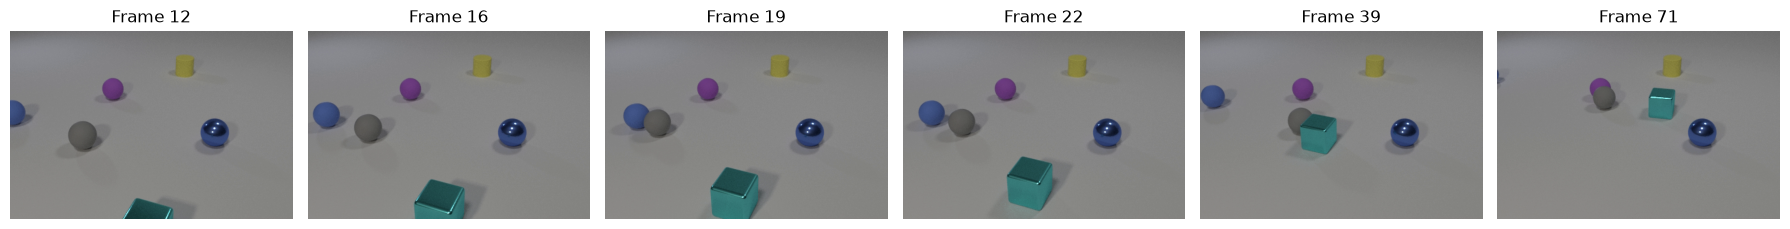

In [23]:

import matplotlib.pyplot as plt
import cv2

video_path = pixel_videos[0]["video_path"]
cap = cv2.VideoCapture(str(video_path))

frames_to_show = [12, 16, 19, 22, 39, 71]

fig, axes = plt.subplots(1, len(frames_to_show), figsize=(18, 4))

for ax, frame_id in zip(axes, frames_to_show):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, frame = cap.read()

    if ok:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame)
        ax.set_title(f"Frame {frame_id}")

    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()


,threshold,TP,FP,FN,precision,recall,F1
0,0.10,102,7,144,0.9358,0.4146,0.5746
1,0.15,106,18,140,0.8548,0.4309,0.5730
2,0.20,109,18,137,0.8583,0.4431,0.5845
3,0.25,113,42,133,0.7290,0.4593,0.5636
4,0.30,106,53,140,0.6667,0.4309,0.5235
5,0.40,84,41,162,0.6720,0.3415,0.4528
6,0.50,64,50,182,0.5614,0.2602,0.3556
7,0.60,50,38,196,0.5682,0.2033,0.2994
8,0.80,30,31,216,0.4918,0.1220,0.1954
9,1.00,16,16,230,0.5000,0.0650,0.1151


Selected training threshold: 0.2
Training F1: 0.5845


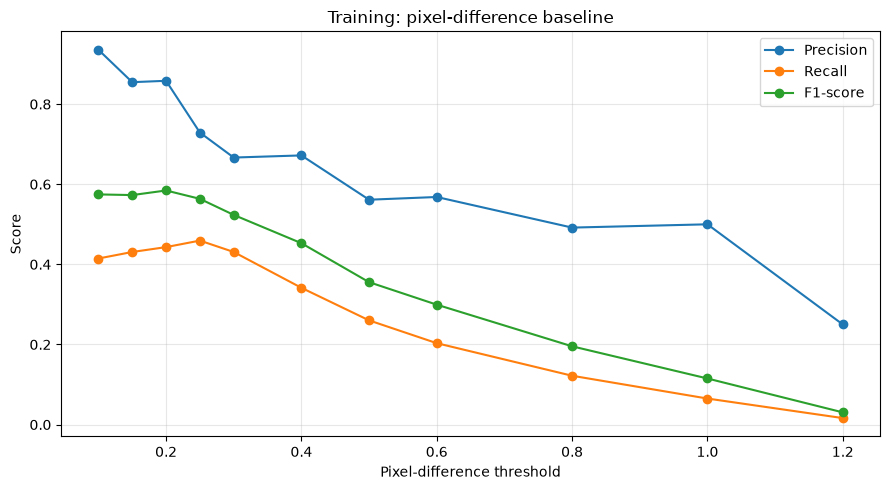

In [24]:

# Threshold search on training videos ONLY
PIXEL_THRESHOLDS = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.40, 0.50, 0.60, 0.80, 1.00, 1.20
]

pixel_train_results = []

for threshold in PIXEL_THRESHOLDS:
    TP = FP = FN = 0

    for video in pixel_videos:
        tp, fp, fn = evaluate_video(
            video["scores"],
            video["collisions"],
            threshold,
            tolerance=TOLERANCE
        )
        TP += tp
        FP += fp
        FN += fn

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    pixel_train_results.append({
        "threshold": threshold,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pixel_train_df = pd.DataFrame(pixel_train_results)

display(pixel_train_df.round(4))

best_pixel_row = pixel_train_df.loc[
    pixel_train_df["F1"].idxmax()
]

PIXEL_THRESHOLD = float(best_pixel_row["threshold"])

print("Selected training threshold:", PIXEL_THRESHOLD)
print("Training F1:", round(float(best_pixel_row["F1"]), 4))

plt.figure(figsize=(9, 5))
plt.plot(
    pixel_train_df["threshold"],
    pixel_train_df["precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    pixel_train_df["threshold"],
    pixel_train_df["recall"],
    marker="o",
    label="Recall"
)
plt.plot(
    pixel_train_df["threshold"],
    pixel_train_df["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Pixel-difference threshold")
plt.ylabel("Score")
plt.title("Training: pixel-difference baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

display(pixel_train_df.round(4))

best_pixel_row = pixel_train_df.loc[
    pixel_train_df["F1"].idxmax()
]

print("Selected threshold:", best_pixel_row["threshold"])
print("Training precision:", best_pixel_row["precision"])
print("Training recall:", best_pixel_row["recall"])
print("Training F1:", best_pixel_row["F1"])


,threshold,TP,FP,FN,precision,recall,F1
0,0.10,102,7,144,0.9358,0.4146,0.5746
1,0.15,106,18,140,0.8548,0.4309,0.5730
2,0.20,109,18,137,0.8583,0.4431,0.5845
3,0.25,113,42,133,0.7290,0.4593,0.5636
4,0.30,106,53,140,0.6667,0.4309,0.5235
5,0.40,84,41,162,0.6720,0.3415,0.4528
6,0.50,64,50,182,0.5614,0.2602,0.3556
7,0.60,50,38,196,0.5682,0.2033,0.2994
8,0.80,30,31,216,0.4918,0.1220,0.1954
9,1.00,16,16,230,0.5000,0.0650,0.1151


Selected threshold: 0.2
Training precision: 0.8582677165354331
Training recall: 0.44308943089430897
Training F1: 0.5844504021447722


In [26]:

# Pixel baseline: held-out validation evaluation
VALIDATION_LIMIT = 100
FIXED_PIXEL_THRESHOLD = 0.2

validation_root = DATA_ROOT / "annotations" / "validation"

validation_files = sorted(
    validation_root.rglob("annotation_*.json")
)[:VALIDATION_LIMIT]

pixel_validation_results = []
missing_validation_videos = []

for path in validation_files:
    with path.open("r", encoding="utf-8") as f:
        ann_val = json.load(f)

    video_path = get_video_path(ann_val["video_filename"])

    if video_path is None:
        missing_validation_videos.append(ann_val["video_filename"])
        continue

    scores = get_pixel_difference_scores(video_path)

    if not scores:
        continue

    ground_truth = [
        event["frame_id"]
        for event in ann_val.get("collision", [])
    ]

    tp, fp, fn = evaluate_video(
        scores,
        ground_truth,
        FIXED_PIXEL_THRESHOLD,
        tolerance=TOLERANCE
    )

    pixel_validation_results.append({
        "annotation": path.name,
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

val_pixel_df = pd.DataFrame(pixel_validation_results)

TP = int(val_pixel_df["TP"].sum()) if not val_pixel_df.empty else 0
FP = int(val_pixel_df["FP"].sum()) if not val_pixel_df.empty else 0
FN = int(val_pixel_df["FN"].sum()) if not val_pixel_df.empty else 0

precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)

print("Validation videos processed:", len(val_pixel_df))
print("Videos not found:", len(missing_validation_videos))
print("Fixed pixel threshold:", FIXED_PIXEL_THRESHOLD)
print(f"TP={TP}, FP={FP}, FN={FN}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


Validation videos processed: 100
Videos not found: 0
Fixed pixel threshold: 0.2
TP=113, FP=28, FN=142
Precision: 0.8014
Recall:    0.4431
F1-score:  0.5707


In [27]:

import pandas as pd

# Static properties of each object
object_properties = {
    obj["object_id"]: obj
    for obj in ann["object_property"]
}

# Select one frame for inspection
FRAME_ID = 19

frame_data = next(
    frame for frame in ann["motion_trajectory"]
    if frame["frame_id"] == FRAME_ID
)

rows = []

for obj in frame_data["objects"]:
    properties = object_properties[obj["object_id"]]

    rows.append({
        "frame": FRAME_ID,
        "object_id": obj["object_id"],
        "color": properties["color"],
        "shape": properties["shape"],
        "material": properties["material"],
        "x": obj["location"][0],
        "y": obj["location"][1],
        "z": obj["location"][2],
        "vx": obj["velocity"][0],
        "vy": obj["velocity"][1],
        "vz": obj["velocity"][2],
        "visible": obj["inside_camera_view"],
    })

scene_state = pd.DataFrame(rows)
display(scene_state.round(3))


,frame,object_id,color,shape,material,x,y,z,vx,vy,vz,visible
0,19,0,blue,sphere,rubber,0.073,-1.710,0.201,0.595,2.578,0.000,True
1,19,1,gray,sphere,rubber,0.275,-1.338,0.201,-1.832,-1.883,0.000,True
2,19,2,cyan,cube,metal,1.846,-0.117,0.199,-2.409,-0.379,0.003,True
3,19,3,purple,sphere,rubber,-0.996,-0.714,0.201,0.000,-0.000,0.000,True
4,19,4,blue,sphere,metal,0.564,0.905,0.201,-0.000,-0.000,0.000,True
5,19,5,yellow,cylinder,rubber,-2.248,0.739,0.201,0.000,-0.000,0.000,True


In [28]:

import numpy as np
import pandas as pd

def get_frame_objects(annotation, frame_id):
    frame = next(
        (
            item for item in annotation["motion_trajectory"]
            if item["frame_id"] == frame_id
        ),
        None
    )

    if frame is None:
        return {}

    return {
        obj["object_id"]: obj
        for obj in frame["objects"]
    }


def compare_scene_states(annotation, frame_id):
    previous = get_frame_objects(annotation, frame_id - 1)
    current = get_frame_objects(annotation, frame_id)
    following = get_frame_objects(annotation, frame_id + 1)

    collision_pairs = {
        tuple(sorted(event["object_ids"]))
        for event in annotation.get("collision", [])
        if event["frame_id"] == frame_id
    }

    properties = {
        obj["object_id"]: obj
        for obj in annotation["object_property"]
    }

    rows = []

    for object_id, obj in current.items():
        if object_id not in previous or object_id not in following:
            continue

        p_prev = np.asarray(
            previous[object_id]["location"], dtype=float
        )
        p_curr = np.asarray(obj["location"], dtype=float)
        p_next = np.asarray(
            following[object_id]["location"], dtype=float
        )

        v_prev = np.asarray(
            previous[object_id]["velocity"], dtype=float
        )
        v_next = np.asarray(
            following[object_id]["velocity"], dtype=float
        )

        rows.append({
            "object_id": object_id,
            "color": properties[object_id]["color"],
            "displacement": np.linalg.norm(p_curr - p_prev),
            "velocity_change": np.linalg.norm(v_next - v_prev),
            "visible": obj["inside_camera_view"],
            "collision_participant": any(
                object_id in pair for pair in collision_pairs
            ),
        })

    return pd.DataFrame(rows)


display(compare_scene_states(ann, 19).round(4))


,object_id,color,displacement,velocity_change,visible,collision_participant
0,0,blue,0.0742,4.1408,True,True
1,1,gray,0.0737,3.6856,True,True
2,2,cyan,0.0684,0.0364,True,False
3,3,purple,0.0000,0.0000,True,False
4,4,blue,0.0000,0.0000,True,False
5,5,yellow,0.0000,0.0000,True,False


In [29]:

import json
import numpy as np
import pandas as pd

from pathlib import Path

ANNOTATION_ROOT = DATA_ROOT / "annotations" / "train"
MAX_VIDEOS = 100
OBJECT_THRESHOLD = 0.5

annotation_files = sorted(
    ANNOTATION_ROOT.rglob("annotation_*.json")
)[:MAX_VIDEOS]

object_rows = []

for path in annotation_files:
    with path.open("r", encoding="utf-8") as f:
        annotation = json.load(f)

    frames = {
        frame["frame_id"]: {
            obj["object_id"]: obj
            for obj in frame["objects"]
        }
        for frame in annotation["motion_trajectory"]
    }

    collision_pairs = {
        (event["frame_id"], tuple(sorted(event["object_ids"])))
        for event in annotation.get("collision", [])
    }

    for frame_id, pair in collision_pairs:
        before = frames.get(frame_id - 1, {})
        after = frames.get(frame_id + 1, {})

        for object_id in pair:
            if object_id not in before or object_id not in after:
                continue

            v_before = np.asarray(
                before[object_id]["velocity"], dtype=float
            )
            v_after = np.asarray(
                after[object_id]["velocity"], dtype=float
            )

            score = float(np.linalg.norm(v_after - v_before))

            object_rows.append({
                "annotation": path.name,
                "frame": frame_id,
                "object_id": object_id,
                "score": score,
                "collision_participant": True,
            })

    # Sample non-participants at the same collision frames
    # for a first exploratory comparison.
    for frame_id, pair in collision_pairs:
        before = frames.get(frame_id - 1, {})
        after = frames.get(frame_id + 1, {})

        for object_id in before.keys() & after.keys():
            if object_id in pair:
                continue

            v_before = np.asarray(
                before[object_id]["velocity"], dtype=float
            )
            v_after = np.asarray(
                after[object_id]["velocity"], dtype=float
            )

            object_rows.append({
                "annotation": path.name,
                "frame": frame_id,
                "object_id": object_id,
                "score": float(np.linalg.norm(v_after - v_before)),
                "collision_participant": False,
            })

object_df = pd.DataFrame(object_rows)

print("Object-frame observations:", len(object_df))
display(
    object_df.groupby("collision_participant")["score"]
    .agg(["count", "mean", "median", "max"])
    .round(4)
)

object_df["predicted_participant"] = (
    object_df["score"] >= OBJECT_THRESHOLD
)

display(
    pd.crosstab(
        object_df["collision_participant"],
        object_df["predicted_participant"],
        rownames=["Actual participant"],
        colnames=["Predicted participant"]
    )
)


Object-frame observations: 1237


,count,mean,median,max
collision_participant,,,,
False,745,0.0327,0.0069,3.3162
True,492,1.3854,1.2747,5.0891


Predicted participant,False,True
Actual participant,,
False,738,7
True,66,426


In [31]:

# Full-video object-level motion-change event detector
# Uses CLEVRER ground-truth trajectories (annotation-based baseline).

import json
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict
from sklearn.metrics import precision_recall_fscore_support

ANNOTATION_ROOT = DATA_ROOT / "annotations" / "train"
MAX_VIDEOS = 100

# Keep these consistent with the existing exploratory experiment.
FRAME_TOLERANCE = 2
MIN_EVENT_GAP = 1

annotation_files = sorted(
    ANNOTATION_ROOT.rglob("annotation_*.json")
)[:MAX_VIDEOS]

if not annotation_files:
    raise FileNotFoundError(
        f"No annotation_*.json files found under {ANNOTATION_ROOT}"
    )


def load_annotation(path):
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)


def get_frame_objects(annotation):
    """Map frame_id -> object_id -> object annotation."""
    return {
        int(frame["frame_id"]): {
            int(obj["object_id"]): obj
            for obj in frame["objects"]
        }
        for frame in annotation["motion_trajectory"]
    }


def get_collision_events(annotation):
    """Return collision events with frame and participant IDs."""
    events = []
    for event in annotation.get("collision", []):
        events.append({
            "frame": int(event["frame_id"]),
            "participants": set(map(int, event["object_ids"])),
        })
    return sorted(events, key=lambda e: e["frame"])


def compute_object_motion_scores(annotation, annotation_name):
    """
    Calculate ||v[t+1] - v[t-1]|| for every object
    observable in both neighboring frames.

    Scores are annotation-derived, not image-derived.
    """
    frames = get_frame_objects(annotation)
    rows = []

    for frame_id in sorted(frames):
        before = frames.get(frame_id - 1, {})
        after = frames.get(frame_id + 1, {})

        for object_id in before.keys() & after.keys():
            try:
                v_before = np.asarray(
                    before[object_id]["velocity"], dtype=float
                )
                v_after = np.asarray(
                    after[object_id]["velocity"], dtype=float
                )
            except (KeyError, TypeError, ValueError):
                continue

            if (
                v_before.shape != v_after.shape
                or not np.all(np.isfinite(v_before))
                or not np.all(np.isfinite(v_after))
            ):
                continue

            score = float(np.linalg.norm(v_after - v_before))

            rows.append({
                "annotation": annotation_name,
                "frame": frame_id,
                "object_id": object_id,
                "score": score,
            })

    return rows


def group_frames_into_intervals(frame_ids, max_gap=MIN_EVENT_GAP):
    """Merge sorted candidate frames when separated by at most max_gap."""
    frame_ids = sorted(set(map(int, frame_ids)))

    if not frame_ids:
        return []

    intervals = []
    start = previous = frame_ids[0]

    for frame_id in frame_ids[1:]:
        if frame_id - previous <= max_gap + 1:
            previous = frame_id
        else:
            intervals.append((start, previous))
            start = previous = frame_id

    intervals.append((start, previous))
    return intervals


def detect_video_events(score_rows, threshold):
    """
    Threshold object scores, aggregate candidate frames across objects,
    then merge nearby frames into video-level event intervals.

    Retain participant candidates by frame for later participant analysis.
    """
    if not score_rows:
        return [], {}

    scores = pd.DataFrame(score_rows)
    scores["candidate"] = scores["score"] >= threshold

    candidate_rows = scores[scores["candidate"]]

    frame_to_objects = defaultdict(set)
    for row in candidate_rows.itertuples(index=False):
        frame_to_objects[int(row.frame)].add(int(row.object_id))

    intervals = group_frames_into_intervals(
        frame_to_objects.keys(), max_gap=MIN_EVENT_GAP
    )

    predictions = []
    for start, end in intervals:
        participants = set()
        for frame_id in range(start, end + 1):
            participants.update(frame_to_objects.get(frame_id, set()))

        predictions.append({
            "start": start,
            "end": end,
            "participants": participants,
        })

    return predictions, dict(frame_to_objects)


def match_events_one_to_one(
    predicted_events,
    ground_truth_events,
    tolerance=FRAME_TOLERANCE,
):
    """
    Greedy one-to-one event matching.

    An event pair is eligible if the predicted interval is within tolerance
    of the ground-truth frame. Each event can match at most once.

    For a final benchmark, audit this protocol and consider maximum-cardinality
    bipartite matching if ambiguous overlapping intervals are common.
    """
    candidates = []

    for pred_idx, pred in enumerate(predicted_events):
        for gt_idx, gt in enumerate(ground_truth_events):
            gt_frame = gt["frame"]

            if pred["start"] - tolerance <= gt_frame <= pred["end"] + tolerance:
                # Prefer predictions whose intervals are closest to the GT frame.
                distance = (
                    0 if pred["start"] <= gt_frame <= pred["end"]
                    else min(
                        abs(gt_frame - pred["start"]),
                        abs(gt_frame - pred["end"]),
                    )
                )
                candidates.append((distance, pred_idx, gt_idx))

    candidates.sort()
    matched_predictions = set()
    matched_ground_truth = set()
    matches = []

    for distance, pred_idx, gt_idx in candidates:
        if (
            pred_idx in matched_predictions
            or gt_idx in matched_ground_truth
        ):
            continue

        matched_predictions.add(pred_idx)
        matched_ground_truth.add(gt_idx)
        matches.append((pred_idx, gt_idx, distance))

    tp = len(matches)
    fp = len(predicted_events) - tp
    fn = len(ground_truth_events) - tp

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "matches": matches,
    }


# Build a per-video score table and collision ground truth.
video_data = {}
all_score_rows = []

for path in annotation_files:
    annotation = load_annotation(path)
    score_rows = compute_object_motion_scores(annotation, path.name)

    video_data[path.name] = {
        "scores": score_rows,
        "ground_truth": get_collision_events(annotation),
    }
    all_score_rows.extend(score_rows)

score_df = pd.DataFrame(all_score_rows)

print(f"Videos: {len(video_data)}")
print(f"Object-frame scores: {len(score_df):,}")
print(f"Videos with collision annotations: "
      f"{sum(bool(v['ground_truth']) for v in video_data.values())}")

display(score_df["score"].describe().to_frame().round(4))


Videos: 100
Object-frame scores: 63,000
Videos with collision annotations: 100


,score
count,63000.0000
mean,0.0397
std,0.2008
min,0.0000
25%,0.0001
50%,0.0167
75%,0.0265
max,5.1094


In [32]:

# Threshold selection on training data.
# Do not report this as held-out/generalization performance.

thresholds = np.quantile(
    score_df["score"].to_numpy(),
    np.linspace(0.50, 0.995, 100),
)
thresholds = np.unique(np.concatenate(([0.0], thresholds)))

threshold_rows = []

for threshold in thresholds:
    total_tp = total_fp = total_fn = 0

    for video_name, data in video_data.items():
        predictions, _ = detect_video_events(
            data["scores"], float(threshold)
        )
        result = match_events_one_to_one(
            predictions, data["ground_truth"]
        )

        total_tp += result["tp"]
        total_fp += result["fp"]
        total_fn += result["fn"]

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp else 0.0
    )
    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn else 0.0
    )
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    threshold_rows.append({
        "threshold": float(threshold),
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    })

threshold_results = pd.DataFrame(threshold_rows).sort_values(
    ["F1", "precision"], ascending=False
).reset_index(drop=True)

display(threshold_results.head(10).round(4))

BEST_OBJECT_THRESHOLD = float(threshold_results.iloc[0]["threshold"])
print("Selected training threshold:", BEST_OBJECT_THRESHOLD)

# Aggregate event metrics at the selected training threshold.
evaluation_rows = []

for video_name, data in video_data.items():
    predictions, frame_to_objects = detect_video_events(
        data["scores"], BEST_OBJECT_THRESHOLD
    )
    result = match_events_one_to_one(
        predictions, data["ground_truth"]
    )

    evaluation_rows.append({
        "video": video_name,
        "ground_truth_events": len(data["ground_truth"]),
        "predicted_events": len(predictions),
        "TP": result["tp"],
        "FP": result["fp"],
        "FN": result["fn"],
        "precision": result["precision"],
        "recall": result["recall"],
        "F1": result["f1"],
    })

event_results_df = pd.DataFrame(evaluation_rows)

total_tp = int(event_results_df["TP"].sum())
total_fp = int(event_results_df["FP"].sum())
total_fn = int(event_results_df["FN"].sum())

micro_precision = (
    total_tp / (total_tp + total_fp)
    if total_tp + total_fp else 0.0
)
micro_recall = (
    total_tp / (total_tp + total_fn)
    if total_tp + total_fn else 0.0
)
micro_f1 = (
    2 * micro_precision * micro_recall
    / (micro_precision + micro_recall)
    if micro_precision + micro_recall else 0.0
)

print("TRAINING-SUBSET EVENT RESULTS — NOT HELD-OUT")
print(f"Threshold: {BEST_OBJECT_THRESHOLD:.6f}")
print(f"TP={total_tp}, FP={total_fp}, FN={total_fn}")
print(f"Micro precision: {micro_precision:.4f}")
print(f"Micro recall:    {micro_recall:.4f}")
print(f"Micro F1:        {micro_f1:.4f}")

display(
    event_results_df[
        ["ground_truth_events", "predicted_events", "TP", "FP", "FN", "F1"]
    ].describe().round(4)
)


,threshold,TP,FP,FN,precision,recall,F1
0,0.2741,236,16,10,0.9365,0.9593,0.9478
1,0.1620,230,11,16,0.9544,0.9350,0.9446
2,0.0913,226,11,20,0.9536,0.9187,0.9358
3,0.4766,223,9,23,0.9612,0.9065,0.9331
4,0.0600,224,43,22,0.8390,0.9106,0.8733
5,0.9595,170,0,76,1.0000,0.6911,0.8173
6,0.0496,221,147,25,0.6005,0.8984,0.7199
7,1.6533,106,0,140,1.0000,0.4309,0.6023
8,0.0167,101,2,145,0.9806,0.4106,0.5788
9,0.0000,100,0,146,1.0000,0.4065,0.5780


Selected training threshold: 0.2741050370658981
TRAINING-SUBSET EVENT RESULTS — NOT HELD-OUT
Threshold: 0.274105
TP=236, FP=16, FN=10
Micro precision: 0.9365
Micro recall:    0.9593
Micro F1:        0.9478


,ground_truth_events,predicted_events,TP,FP,FN,F1
count,100.00,100.0000,100.0000,100.0000,100.0000,100.0000
mean,2.46,2.5200,2.3600,0.1600,0.1000,0.9502
std,0.61,0.6432,0.5777,0.3949,0.3015,0.0969
min,1.00,1.0000,1.0000,0.0000,0.0000,0.6667
25%,2.00,2.0000,2.0000,0.0000,0.0000,1.0000
50%,2.00,2.5000,2.0000,0.0000,0.0000,1.0000
75%,3.00,3.0000,3.0000,0.0000,0.0000,1.0000
max,4.00,4.0000,4.0000,2.0000,1.0000,1.0000


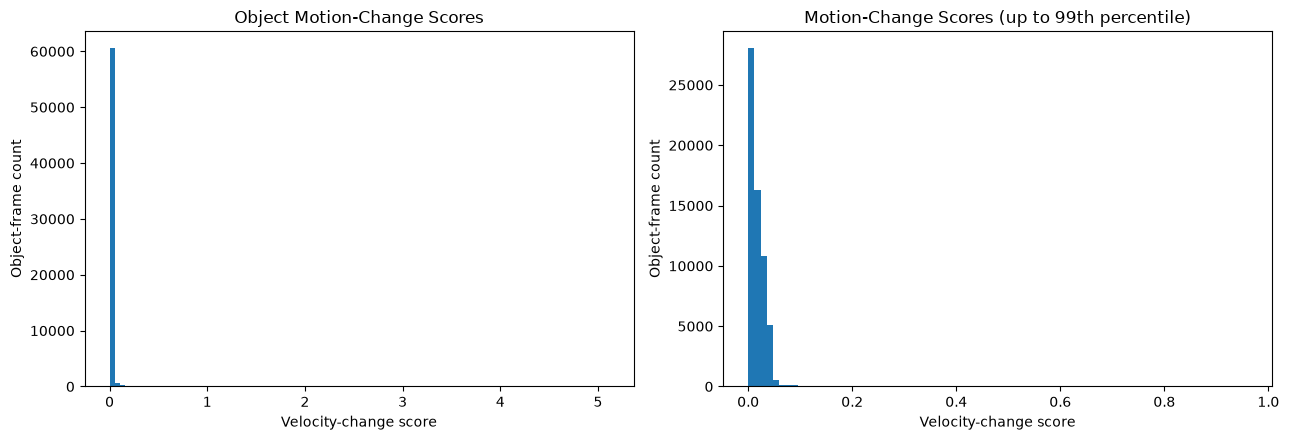

Score quantiles:


,score
0.500,0.01669
0.750,0.02647
0.900,0.03793
0.950,0.04629
0.990,0.95945
0.995,1.65327
0.999,2.75616
1.000,5.10944


In [33]:

import matplotlib.pyplot as plt
import numpy as np

scores = score_df["score"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Full distribution
axes[0].hist(scores, bins=100)
axes[0].set_title("Object Motion-Change Scores")
axes[0].set_xlabel("Velocity-change score")
axes[0].set_ylabel("Object-frame count")

# Zoom into the bulk of the distribution
upper = np.quantile(scores, 0.99)
axes[1].hist(scores[scores <= upper], bins=80)
axes[1].set_title("Motion-Change Scores (up to 99th percentile)")
axes[1].set_xlabel("Velocity-change score")
axes[1].set_ylabel("Object-frame count")

plt.tight_layout()
plt.show()

print("Score quantiles:")
display(
    score_df["score"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00])
    .rename("score")
    .to_frame()
    .round(5)
)
